# Visium DLPFC with histology

Run every cell in order after installing STAIG and Jupyter. Set `STAIG_DATA` to an unpacked `Dataset` directory, or let `download=True` fetch the missing slice. No machine-specific paths or GPU operations are needed.

This example uses **all labelled spots of slice 151673**, the released BYOL H&E embeddings and **30 CPU epochs**. It validates the workflow, not the published accuracy. Fresh BYOL extraction is described in the [histology tutorial](https://y-itao.github.io/STAIG/tutorials/visium_with_histology/). The paper's DLPFC comparison is [Figure 2](https://www.nature.com/articles/s41467-025-56276-0/figures/2).

In [1]:
import os
import warnings

# Compact warnings preserve their message without machine-specific source paths.
def show_warning(message, category, filename, lineno, file=None, line=None):
    print(f"{category.__name__}: {message}")
warnings.showwarning = show_warning

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import staig
from staig import datasets, img, metrics, pl, pp

torch.set_num_threads(min(4, os.cpu_count() or 1))
plt.rcParams.update({"figure.figsize": (4.5, 4), "figure.dpi": 85})
root = os.getenv("STAIG_DATA")  # Unpacked Dataset root; None uses ./Dataset.
device = "cpu"  # Deliberately avoids the shared GPU.
print({"staig": staig.__version__, "torch": torch.__version__, "device": device})

{'staig': '2.0.0', 'torch': '2.11.0+cu128', 'device': 'cpu'}


## Load the slice and released H&E features

The loader drops unlabelled spots before attaching the released embedding rows. Their order must match the retained barcodes.

In [2]:
adata = datasets.load_dlpfc("151673", root=root, download=True)
released_features = adata.obsm["image_features"].copy()
img.extract_image_features(adata, method=released_features)
assert released_features.shape == (adata.n_obs, 2048)
assert adata.obs["ground_truth"].notna().all()
print({"spots": adata.n_obs, "genes": adata.n_vars,
       "image_features": adata.obsm["image_features"].shape})

[staig] load_labels: dropped 28 unlabelled spots


{'spots': 3611, 'genes': 33538, 'image_features': (3611, 2048)}


## Train and cluster

`run` mutates `adata` and returns the fitted model. The default Python GMM and single-slice spatial refinement need no R.

In [3]:
model = staig.run(adata, n_clusters=7, preset="visium", epochs=30,
                  device=device, seed=0, loss_chunk_size=256, verbose=False)
assert adata.obsm["X_staig"].shape == (adata.n_obs, 64)
assert np.isfinite(adata.obsm["X_staig"]).all()
assert np.isfinite(model.history["loss"]).all()
assert len(model.history["loss"]) == model.config.epochs
assert adata.obs["staig_domain"].notna().all()
print({"spots": adata.n_obs, "genes": adata.n_vars,
       "input_features": adata.obsm["X_staig_input"].shape[1],
       "epochs": model.config.epochs,
       "edge_mode": adata.uns["staig"]["edge_removal"]["mode"],
       "negative_mask": adata.uns["staig"]["negatives"],
       "n_negatives": adata.uns["staig"]["n_negatives"]})

[staig] preprocess: 3611 spots x 3000 HVGs -> obsm['X_staig_input']


{'spots': 3611, 'genes': 33538, 'input_features': 3000, 'epochs': 30, 'edge_mode': 'image', 'negative_mask': 'pseudo_label', 'n_negatives': 'all'}


## Inspect the domains

Labels are arbitrary domain identifiers; their colors need not match the annotation colors.

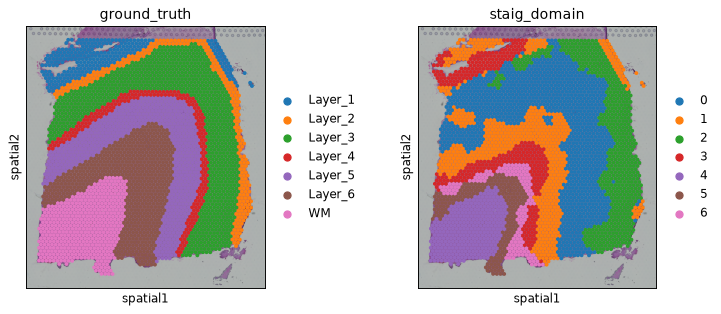

In [4]:
pl.spatial(adata, color=["ground_truth", "staig_domain"], show=False)
plt.show()


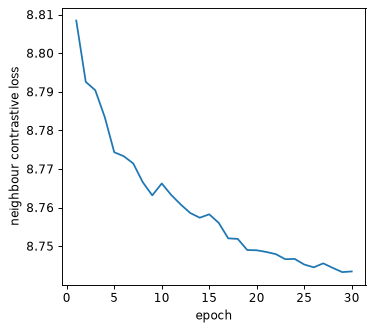

Written obsm keys: ['X_staig', 'X_staig_input', 'image_features', 'image_pcs', 'spatial']
Written obsp keys: ['spatial_connectivities', 'staig_edge_prob']
Recorded sections: ['cluster', 'config', 'edge_removal', 'graph', 'history', 'image', 'metrics', 'n_negatives', 'negatives', 'preprocess', 'source', 'timings']


In [5]:
pl.loss_curve(adata)
plt.tight_layout()
plt.show()
print("Written obsm keys:", sorted(adata.obsm.keys()))
print("Written obsp keys:", sorted(adata.obsp.keys()))
print("Recorded sections:", sorted(adata.uns["staig"].keys()))